## **Exercise: Skip-Gram Model with Negative Sampling**

The Skip-Gram model predicts context words given a target word in a sequence. It learns word embeddings by trying to bring target and context words closer in the embedding space while pushing unrelated words apart. This uses **negative sampling** to reduce computation.

---

### **Mathematical Formulation**

For a sequence of words $w_1, w_2, \ldots, w_T$, the model tries to maximize the following objective:

$$
\mathcal{L} = \frac{1}{T} \sum_{t=1}^{T} \sum_{\substack{-c \leq j \leq c \\ j \neq 0}} \Big[ \log \sigma\big(\mathbf{v}_{w_{t+j}}^\top \mathbf{v}_{w_t}\big) + \sum_{k=1}^K \log \sigma\big(-\mathbf{v}_{w_k}^\top \mathbf{v}_{w_t}\big) \Big]
$$

---

### **Breaking it Down**

1. **Objective:**  
   - The goal is to:
     - Maximize the similarity between a target word ($w_t$) and its context words ($w_{t+j}$).
     - Minimize the similarity between the target word and randomly sampled negative words ($w_k$).

2. **Key Terms:**
   - $\sigma(x)$: The **sigmoid function**, which gives probabilities:
     $
     \sigma(x) = \frac{1}{1 + \exp(-x)}
     $
   - $\mathbf{v}_{w_t}$: The **embedding** of the target word $w_t$.
   - $\mathbf{v}_{w_{t+j}}$: The **embedding** of a context word.
   - $\mathbf{v}_{w_k}$: The **embedding** of a negative sampled word.
   - $c$: The window size (how many words around the target to consider as context).
   - $K$: The number of negative samples per positive pair.

---

### **Loss Function: Binary Cross-Entropy**

The model performs **binary classification** for each pair (target, context/class) with two classes:
- **Class 1**: The pair is a true (target, context) pair.
- **Class 0**: The pair is a false (target, negative) pair.

The predicted probability $\hat{y}$ is obtained using the sigmoid function $\sigma(x)$, which outputs values in the range $[0, 1]$.

The loss function is **binary cross-entropy**, defined as:

$$
\text{Binary Cross-Entropy Loss} = -\frac{1}{N} \sum_{i=1}^{N} \Big[ y_i \log(\hat{y}_i) + (1 - y_i) \log(1 - \hat{y}_i) \Big]
$$

#### **Explanation:**
1. **Positive Pairs:**
   - $y = 1$, so the loss includes $-\log(\hat{y})$, where $\hat{y}$ is the probability that the target-context pair is real.
   - Encourages $\hat{y}$ to be close to 1 for real pairs.

2. **Negative Pairs:**
   - $y = 0$, so the loss includes $-\log(1 - \hat{y})$, where $\hat{y}$ is the probability that the target-negative pair is real.
   - Encourages $\hat{y}$ to be close to 0 for negative pairs.

3. **Relation to Sigmoid:**
   - The sigmoid function converts the dot product between word embeddings into a probability for classification. For example:
     - If embeddings are similar, $\sigma(x)$ approaches 1, favoring positive pairs.
     - If embeddings differ, $\sigma(x)$ approaches 0, favoring negative pairs.

---

### **How It Works**

1. **Positive Terms:**  
   $$
   \log \sigma\big(\mathbf{v}_{w_{t+j}}^\top \mathbf{v}_{w_t}\big)
   $$
   - Encourages embeddings of target ($w_t$) and context words ($w_{t+j}$) to be closer.

2. **Negative Terms:**  
   $$
   \log \sigma\big(-\mathbf{v}_{w_k}^\top \mathbf{v}_{w_t}\big)
   $$
   - Encourages embeddings of target ($w_t$) and unrelated words ($w_k$) to be far apart.

3. **Negative Sampling:**  
   - Instead of computing similarity with all words in the vocabulary, the model samples $K$ random words for each target-context pair, making training faster.




In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Embedding, Reshape, Activation, Input, Dot
from tensorflow.keras.utils import get_file
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import skipgrams
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt


def preprocess_corpus(corpus):
    """
    Tokenize and preprocess the corpus into sequences of word indices.

    Args:
        corpus (list of str): A list of sentences (text corpus).

    Returns:
        tokenizer: Fitted tokenizer containing word-index mappings.
        sequences: A list of tokenized sentences.
        vocab_size: The total number of unique words in the corpus, plus one for padding.
    """
    tokenizer = Tokenizer()
    tokenizer.fit_on_texts(corpus)
    sequences = tokenizer.texts_to_sequences(corpus)
    vocab_size = len(tokenizer.word_index) + 1
    return tokenizer, sequences, vocab_size

# Testing Tokenizer on toy example
example_sents = ["the cat plays with the toy", "The dog plays"]
tokenizer, sequences, vocab_size = preprocess_corpus(example_sents)

print("Index to Word:",tokenizer.index_word)
print("Sequences:",sequences)
print("Vocab size:",vocab_size)



Index to Word: {1: 'the', 2: 'plays', 3: 'cat', 4: 'with', 5: 'toy', 6: 'dog'}
Sequences: [[1, 3, 2, 4, 1, 5], [1, 6, 2]]
Vocab size: 7


In [3]:
def generate_skipgram_pairs(sequences, window_size, vocab_size, negative_samples, shuffle=False):
    """
    Goal:
        Generate training pairs (center word, context word) and their labels for Skip-gram.

    Args:
        sequences (list of list of int): Corpus represented as sequences of word indices.
        window_size (int): Context window size for generating pairs.
        vocab_size (int): Total number of unique words in the vocabulary.
        negative_samples (int): Number of negative samples per positive sample.
        shuffle (bool): Whether to shuffle the generated pairs.

    Returns:
        center_words (numpy array): Array of center words.
        context_words (numpy array): Array of context words (positive/negative).
        labels (numpy array): Array of labels (1 for positive pairs, 0 for negative pairs).

    Example:
        Input:
              [[1, 3, 2, 4, 1, 5], [1, 6, 2]]
              Vocab: {1: 'the', 2: 'plays', 3: 'cat', 4: 'with', 5: 'toy', 6: 'dog'}
        Output:
              center_words = [1 1 3 3 3 2 2 2 2 4 4 4 4 1 1 1 5 5 1 5 2 4 1 4 5 1 4 3 3 3 1 2 4 2 1 2 1
              5 2 4 1 4 5 1 4 3 3 3 1 2 4 2 1 2 1 5 2 4 1 4 5 1 4 3 3 3 1 2 4 2 1 2 1 5
              2 4 1 4 5 1 4 3 3 3 1 2 4 2 1 2 1 1 6 6 2 2 1 6 2 2 1 6 1 6 2 2 1 6 1 6 2
              2 1 6 1 6 2 2 1 6]
              context_words = [3 2 1 2 4 1 3 4 1 3 2 1 5 2 4 5 4 1 1 6 4 5 1 4 1 5 3 6 5 3 5 2 6 1 1 6 2
              3 1 2 1 4 3 4 6 3 2 3 3 2 6 3 6 6 6 1 5 6 2 5 6 2 2 4 4 3 6 6 5 2 6 3 1 2
              1 3 4 3 1 2 5 6 3 2 6 4 4 6 4 2 6 2 1 2 1 6 6 5 4 5 4 3 2 2 5 4 1 1 1 2 6
              2 6 4 5 1 4 4 5 4]
              labels = [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
              0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
              0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
              0 0 0 0 0 0 0 0 0]
    """
    center_words = []
    context_words = []
    labels = []
    
    for seq in sequences:
        # FIXED: skipgrams returns 2 values, not 3
        pairs, pair_labels = skipgrams(
            seq, 
            vocab_size, 
            window_size=window_size,
            negative_samples=negative_samples, 
            shuffle=shuffle
        )
        
        # pairs is a list of (target, context) tuples
        # pair_labels is a list of labels (1 or 0)
        for (target, context), label in zip(pairs, pair_labels):
            center_words.append(target)
            context_words.append(context)
            labels.append(label)
    
    return np.array(center_words), np.array(context_words), np.array(labels)

# Testing Skip-gram pair generation on toy example





example_sents = [
    "the cat plays with the toy",
    "The dog plays"
]

window_size = 2
# Preprocess the corpus
tokenizer, sequences, vocab_size = preprocess_corpus(example_sents)
print(sequences)
print(tokenizer.index_word)
# Generate skip-gram pairs

center_words,context_words,labels = generate_skipgram_pairs(sequences, window_size=window_size, vocab_size=vocab_size,negative_samples=window_size*2)
print(center_words)
print(context_words)
print(labels)




[[1, 3, 2, 4, 1, 5], [1, 6, 2]]
{1: 'the', 2: 'plays', 3: 'cat', 4: 'with', 5: 'toy', 6: 'dog'}
[1 1 3 3 3 2 2 2 2 4 4 4 4 1 1 1 5 5 2 5 4 1 3 4 4 5 3 2 1 2 1 3 1 2 1 4 2
 5 4 1 3 4 4 5 3 2 1 2 1 3 1 2 1 4 2 5 4 1 3 4 4 5 3 2 1 2 1 3 1 2 1 4 2 5
 4 1 3 4 4 5 3 2 1 2 1 3 1 2 1 4 1 1 6 6 2 2 1 6 6 2 2 1 1 6 6 2 2 1 1 6 6
 2 2 1 1 6 6 2 2 1]
[3 2 1 2 4 1 3 4 1 3 2 1 5 2 4 5 4 1 2 4 2 3 2 6 5 4 4 1 2 6 5 3 1 4 2 4 3
 6 1 1 5 4 6 4 6 4 3 2 3 5 2 3 6 3 1 4 1 2 5 5 2 2 6 4 3 5 5 2 5 4 5 5 6 6
 6 3 5 2 3 6 4 1 2 1 6 6 5 4 2 3 6 2 1 2 1 6 6 6 3 3 2 4 4 1 1 2 4 5 3 2 4
 1 4 3 2 3 6 5 5 1]
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0]


In [4]:
def create_skipgram_model(vocab_size, embedding_dim):
    """
    Goal:
        Build and compile a Skip-gram model.

    Args:
        vocab_size (int): Total vocabulary size.
        embedding_dim (int): Dimension of the embedding vectors.

    Returns:
        model (Model): Compiled Skip-gram model.

    Example:
        Input: vocab_size = 7, embedding_dim = 20
        Output: A compiled Keras model for Skip-gram training.
    ------------------------------------------------------------------------
    Steps to Build the Model using Keras

    Input for Center (Target) Words:
        Input layer for the target word (wt) as an integer index.
        Embedding layer maps this index to a dense vector of size embedding_dim.

    Input for Context Words:
        Input layer for the context word (wt+j or negative samples wk).
        Embedding layer maps the context word index to a dense vector of size embedding_dim.

    Dot Product:
        The similarity between the center and context words is computed using a dot product of their embeddings.

    Reshape:
        Flatten the dot product output to make it compatible with the next layer.

    Sigmoid Activation:
        Apply a sigmoid function to output a probability for binary classification (positive/negative pair).

    Loss and Optimization:
        Use binary cross-entropy as the loss function.
        Use the Adam optimizer for training.

    """
    center_input = Input(shape=(1,), name='Center_Word')
    context_input = Input(shape=(1,), name='Context_Word')
    
    embedding_layer = Embedding(vocab_size, embedding_dim, name='Word_Embedding')
    
    center_embedding = embedding_layer(center_input)
    context_embedding = embedding_layer(context_input)
    
    dot_product = Dot(axes=-1, name='Dot_Product')([center_embedding, context_embedding])
    reshaped = Reshape((1,), name='Reshape')(dot_product)
    output = Activation('sigmoid', name='Sigmoid_Output')(reshaped)
    
    model = Model(inputs=[center_input, context_input], outputs=output)
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    
    return model

def print_model_architecture(model, input_shape):
    """Print the model architecture (layers, names, and shapes)."""
    # Build the model by providing an example input shape (batch size, sequence length).

    model.build(input_shape)

    # Print model summary to see the details about each layer and its output shapes.
    print("\nModel Architecture:")
    print("=" * 40)
    model.summary()  # This prints out the architecture of the model (layer by layer).
    print("=" * 40)


model = create_skipgram_model(vocab_size, embedding_dim=20)
print_model_architecture(model, input_shape=(None, 1))




Model Architecture:


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ Center_Word         │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Context_Word        │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Word_Embedding      │ (None, 1, 20)     │        140 │ Center_Word[0][0… │
│ (Embedding)         │                   │            │ Context_Word[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Dot_Product (Dot)   │ (None, 1, 1)      │          0 │ Word_Embedding[0… │
│                     │                   │            │ Word_Embedding[1… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Reshape (Reshape)   │ (None, 1)         │          0 │ Dot_Product[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Sigmoid_Output      │ (None, 1)         │          0 │ Reshape[0][0]     │
│ (Activation)        │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 140 (560.00 B)

 Trainable params: 140 (560.00 B)

 Non-trainable params: 0 (0.00 B)

In [5]:



def train_model(model, center_words, context_words, y_train, epochs=300, batch_size=4):
    """
    Goal:
        Train the Skip-gram model using the generated skip-gram pairs.

    Args:
        model (Model): Compiled Skip-gram model.
        center_words (numpy array): Array of center words.
        context_words (numpy array): Array of context words.
        y_train (numpy array): Labels for the pairs (1 for positive, 0 for negative).
        epochs (int): Number of training epochs.
        batch_size (int): Batch size for training.

    Returns:
        history (History): Training history object with loss metrics.

    Example:
        Input:
            center_words = [1, 2, 3], context_words = [2, 3, 4], y_train = [1, 0, 1]
            epochs = 10, batch_size = 2
        Output: Model trained for 10 epochs with specified data.
    """
    early_stopping = EarlyStopping(
        monitor='loss',
        patience=20,
        min_delta=0.0001
    )
    history = model.fit(
        [center_words, context_words],  # Separate inputs for center and context words
        y_train,  # Labels
        epochs=epochs,
        batch_size=batch_size,
        callbacks=[early_stopping],  # Stop early if no improvement
        verbose=1
    )
    return history

# Model parameters
window_size = 2
embedding_dim = 20
negative_samples = window_size * 2

# Create and preprocess corpus
corpus = [
    "the cat plays with toy",
    "the dog plays with toy",
    "the bird plays with toy",
    "the cat eats food",
    "the dog eats food",
    "the bird eats food",
    "people love pets",
    "children like pets",
    "parents love pets",
    "people love animals",
    "children like animals",
    "parents love animals",
    "the cat runs fast",
    "the dog runs fast",
    "the bird flies fast",
    "the cat loves food",
    "the dog loves food",
    "the bird loves food",
    "people like toys",
    "children like toys",
    "parents like toys",
    "people love toys",
    "children love toys",
    "parents love toys",
]
tokenizer, sequences, vocab_size = preprocess_corpus(corpus)

# Generate skip-gram pairs
center_words, context_words, y_train = generate_skipgram_pairs(
    sequences,
    window_size=2,
    vocab_size=vocab_size,
    negative_samples=4,
    shuffle=True
)

print("Center words:", center_words)
print("Context words:", context_words)
print("Labels:", y_train)


# Create and train model
model = create_skipgram_model(vocab_size, embedding_dim)

# Print model architecture
print_model_architecture(model, input_shape=(None, 1))

# Train the model
history = train_model(model, center_words, context_words, y_train, epochs=300, batch_size=4)

Center words: [14  1  1 ... 11  4  2]
Context words: [11  1 17 ... 17  6  4]
Labels: [0 0 0 ... 0 0 1]

Model Architecture:


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ Center_Word         │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Context_Word        │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Word_Embedding      │ (None, 1, 20)     │        440 │ Center_Word[0][0… │
│ (Embedding)         │                   │            │ Context_Word[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Dot_Product (Dot)   │ (None, 1, 1)      │          0 │ Word_Embedding[0… │
│                     │                   │            │ Word_Embedding[1… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Reshape (Reshape)   │ (None, 1)         │          0 │ Dot_Product[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Sigmoid_Output      │ (None, 1)         │          0 │ Reshape[0][0]     │
│ (Activation)        │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 440 (1.72 KB)

 Trainable params: 440 (1.72 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/300
255/255 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5725 - loss: 0.6929
Epoch 2/300
255/255 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6235 - loss: 0.6890
Epoch 3/300
255/255 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6029 - loss: 0.6791
Epoch 4/300
255/255 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6108 - loss: 0.6681
Epoch 5/300
255/255 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6118 - loss: 0.6608
Epoch 6/300
255/255 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6157 - loss: 0.6571
Epoch 7/300
255/255 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6167 - loss: 0.6543
Epoch 8/300
255/255 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6284 - loss: 0.6520
Epoch 9/300
255/255 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6275 - loss: 0.6496
Epoch 10/300
255/255 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6343 - loss: 0.6480
Epoch 11/300
255/255 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6373 - loss: 0.6459
Epoch 12/300
255/255 ━━━━━━━━━━━━━━━━━━━━

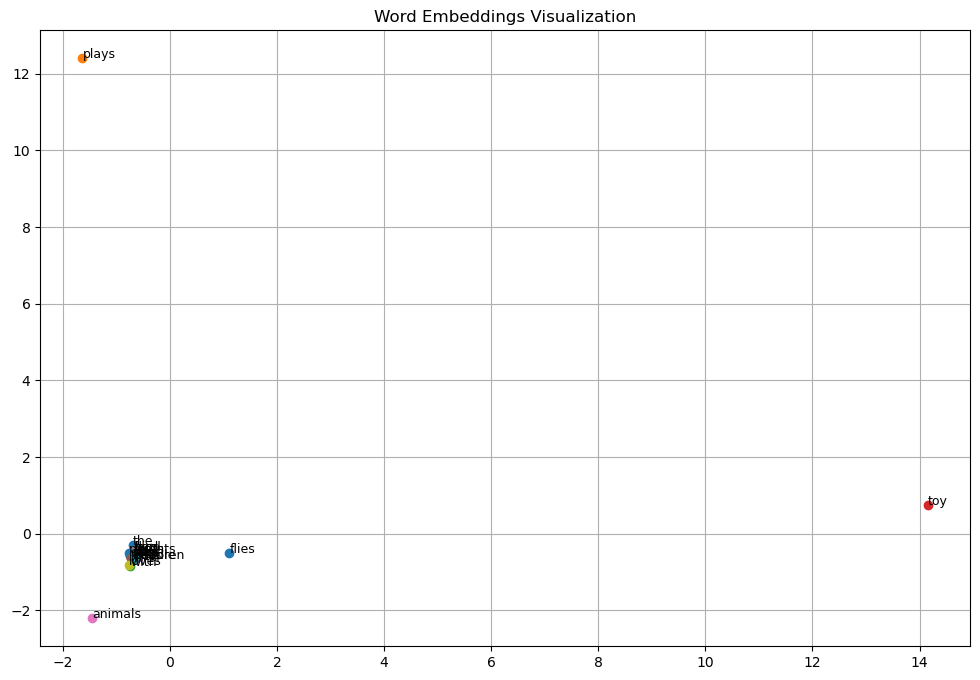

In [6]:
def get_word_vector(word, tokenizer, model):
    """
    Get embedding vector for a word.

    The goal of this function is to retrieve the embedding vector of a given word from the trained Skip-gram model.
    The function uses the tokenizer to look up the word index and fetch the corresponding embedding vector from the model.

    Input:
        - word (str): The word for which we want to retrieve the embedding vector.
        - tokenizer (keras.preprocessing.text.Tokenizer): The tokenizer used during model training. It provides the word index.
        - model (keras.models.Sequential): The trained Skip-gram model that contains the word embedding layer.

    Output:
        - (numpy.ndarray or None): The embedding vector of the word as a numpy array if the word is in the vocabulary.
          Returns `None` if the word is not found in the tokenizer's word index.

    Hint: use model.get_layer('layername').get_weights()[0] to get the weights of a given layer

    Example:
        - Input: word="king", tokenizer=tokenizer_object, model=model_object
        - Output: array([0.123, 0.456, ..., -0.789])  # The embedding vector of "king"

    If the word is not found:
        - Input: word="unknown_word", tokenizer=tokenizer_object, model=model_object
        - Output: None
    """
    if word not in tokenizer.word_index:
        return None
    return model.get_layer('Word_Embedding').get_weights()[0][tokenizer.word_index[word]]




def plot_word_embeddings(model, tokenizer):
    """Visualize word embeddings using PCA"""

    # Get the embedding weights from the model's 'Word_Embedding' layer
    # model.get_layer('Word_Embedding').get_weights()[0] returns the weight matrix of the embedding layer
    # This matrix has a shape of (vocab_size, embedding_dim), where each row is a word's embedding.
    embeddings = model.get_layer('Word_Embedding').get_weights()[0]

    # Apply PCA (Principal Component Analysis) to reduce the dimensionality of the embeddings
    # from high-dimensional space (e.g., 100 dimensions) to 2 dimensions for visualization.
    pca = PCA(n_components=2)  # We want to reduce the embeddings to 2D for plotting
    reduced_embeddings = pca.fit_transform(embeddings)  # Fit the PCA model and transform the embeddings to 2D

    # Create a plot to visualize the 2D word embeddings
    plt.figure(figsize=(12, 8))  # Set the figure size for the plot

    # Loop through the vocabulary and plot each word's reduced embedding (2D coordinates)
    for i in range(1, len(tokenizer.word_index) + 1):
        word = tokenizer.index_word[i]  # Get the word from the index
        x, y = reduced_embeddings[i]  # Get the 2D coordinates of the word's embedding

        # Plot the word's embedding as a scatter point
        plt.scatter(x, y)

        # Annotate the scatter point with the word (placing the word label at the coordinates)
        plt.annotate(word, (x, y), fontsize=9)

    # Set the title for the plot
    plt.title("Word Embeddings Visualization")

    # Enable the grid for better visibility of the plot
    plt.grid(True)

    # Show the plot
    plt.show()



plot_word_embeddings(model, tokenizer)


In [7]:
def find_similar_words(word, tokenizer, model, top_n=3):
    """
    Find the most similar words using cosine similarity, excluding the input word itself.

    Args:
        word (str): The word for which we want to find similar words.
        tokenizer (Tokenizer): The tokenizer used during model training.
        model (Model): The trained Skip-gram model.
        top_n (int, optional): Number of most similar words to return (default is 3).

    Returns:
        list of tuples: A list of (word, similarity) pairs, sorted by similarity in descending order.

    Example:
        Input: word="cat", tokenizer=tokenizer_object, model=model_object, top_n=3
        Output: [("dog", 0.93), ("bird", 0.82), ("toy", 0.71)]
    """

    # Helper function to get the embedding vector for the input word
    def get_word_vector(word, tokenizer, model):
        if word not in tokenizer.word_index:
            return None
        word_idx = tokenizer.word_index[word]
        embeddings = model.get_layer('Word_Embedding').get_weights()[0]
        return embeddings[word_idx]

    # Get the embedding vector for the input word
    word_vector = get_word_vector(word, tokenizer, model)

    # If the word is not in the vocabulary, return an empty list
    if word_vector is None:
        return []

    # Get all word embeddings from the embedding layer of the model
    embeddings = model.get_layer('Word_Embedding').get_weights()[0]

    # Compute cosine similarities between the input word and all other words
    similarities = cosine_similarity([word_vector], embeddings)[0]

    most_similar = []  # List to store the most similar words
    sorted_indices = np.argsort(similarities)[::-1]  # Sort similarities in descending order

    # Collect the top_n most similar words, excluding the input word itself
    for idx in sorted_indices:
        if len(most_similar) >= top_n:
            break
        if idx != 0 and idx in tokenizer.index_word and tokenizer.index_word[idx] != word:
            similar_word = tokenizer.index_word[idx]
            similarity = similarities[idx]
            most_similar.append((similar_word, round(similarity, 3)))  # Round similarity for clarity

    return most_similar


print("cat:",find_similar_words("cat", tokenizer, model, top_n=3))
print("dog:",find_similar_words("dog", tokenizer, model, top_n=3))
print("love:",find_similar_words("love", tokenizer, model, top_n=3))
print("people:",find_similar_words("people", tokenizer, model, top_n=3))
print("toy:",find_similar_words("toy", tokenizer, model, top_n=3))
print("the:",find_similar_words("the", tokenizer, model, top_n=3))

cat: [('animals', 0.644), ('the', 0.383), ('food', 0.365)]
dog: [('runs', 0.554), ('food', 0.547), ('pets', 0.534)]
love: [('people', 0.759), ('toys', 0.703), ('children', 0.582)]
people: [('love', 0.759), ('toys', 0.662), ('parents', 0.624)]
toy: [('flies', 0.859), ('with', 0.009), ('plays', 0.004)]
the: [('food', 0.839), ('eats', 0.657), ('runs', 0.478)]
